# 03 — โมเดลเรียนรู้อย่างไร และส่วนใดเหมือน/ต่างจากบทความ

โมเดลหลักมีแนวคิดสามขั้น:

1. **Stage 1 — Classification pretraining:** ให้ CNN เรียนรู้รูปแบบที่สัมพันธ์กับ sleep stage
2. **Stage 2 — Supervised contrastive learning:** ดึง representation ของคลาสเดียวกันให้ใกล้ และคลาสต่างกันให้ออกห่าง
3. **Stage 3 — Sequential classification:** ส่งลำดับ representation เข้า GRU สองชั้นเพื่อใช้บริบทตามเวลา

สมุดนี้อ่าน protocol และ metrics provenance ที่ r19 เขียนไว้จริง ไม่ build หรือ train TensorFlow model

In [1]:
from pathlib import Path
import sys

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "paper_faithful").is_dir())
sys.path.insert(0, str(ROOT / "walkthrough"))

import matplotlib.pyplot as plt
import numpy as np
from walkthrough_lib import *

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
print(f"Project root : {PROJECT_ROOT}")
print(f"Bulk artifacts: {BULK_ROOT}")

Project root : C:\Users\Acer\OneDrive\Documents\เป้าๆรวยๆๆๆ\sleep_stage_reproduction
Bulk artifacts: E:\blp\sleep_stage_reproduction


## 1. แผนภาพ pipeline

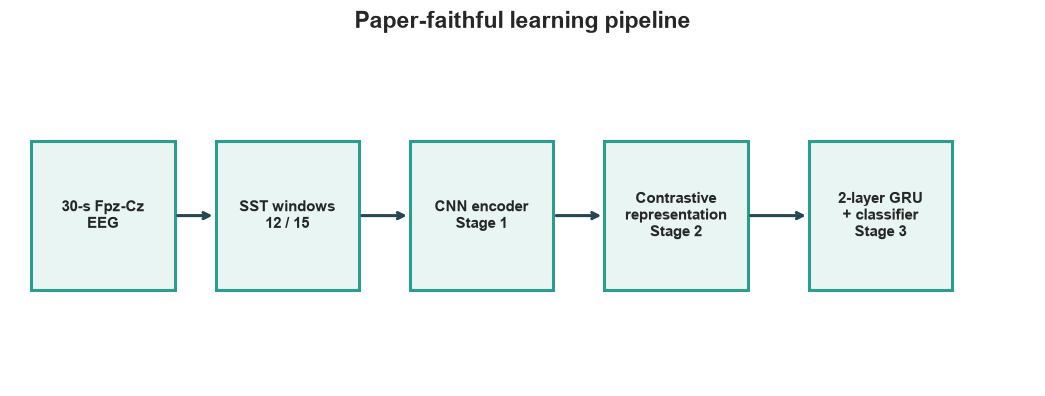

In [2]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.axis("off")
boxes = [
    (0.02, "30-s Fpz-Cz\nEEG"),
    (0.20, "SST windows\n12 / 15"),
    (0.39, "CNN encoder\nStage 1"),
    (0.58, "Contrastive\nrepresentation\nStage 2"),
    (0.78, "2-layer GRU\n+ classifier\nStage 3"),
]
for x, label in boxes:
    ax.add_patch(plt.Rectangle((x, 0.28), 0.14, 0.44, facecolor="#e9f5f2", edgecolor="#2a9d8f", linewidth=2))
    ax.text(x + 0.07, 0.5, label, ha="center", va="center", fontsize=10, weight="bold")
for (x1, _), (x2, _) in zip(boxes[:-1], boxes[1:]):
    ax.annotate("", xy=(x2, 0.5), xytext=(x1 + 0.14, 0.5), arrowprops=dict(arrowstyle="->", lw=2, color="#264653"))
ax.set_title("Paper-faithful learning pipeline", fontsize=15, pad=12)
plt.show()

## 2. Hyperparameters ที่ถูกบันทึกในผล r19

คอลัมน์ `paper_exact` บอกความตรงกับ protocol ในระดับ stage ไม่ได้แปลว่าผลรวมทั้ง run เป็น full reproduction

In [3]:
specs = r19_stage_specs()
rows = []
for spec in specs:
    rows.append({
        "stage": spec["stage"],
        "epochs": spec["epochs"],
        "optimizer": spec["optimizer"],
        "learning_rate": spec["learning_rate"],
        "microbatch": spec["microbatch"],
        "effective_batch": spec["effective_batch"],
        "paper_exact": spec["paper_exact"],
    })
print_records(rows, ["stage", "epochs", "optimizer", "learning_rate", "microbatch", "effective_batch", "paper_exact"])

stage  | epochs | optimizer | learning_rate | microbatch | effective_batch | paper_exact
-------+--------+-----------+---------------+------------+-----------------+------------
stage1 | 20     | AdamW     | 0.05          | 128        | 128             | True       
stage2 | 20     | SGD       | 0.1           | 128        | 128             | True       
stage3 | 20     | SGD       | 0.1           | 1          | 128             | False      


## 3. จุดดัดแปลงเพื่อให้รันบนเครื่องนี้ได้

Stage 3 ต้องการ batch 128 แต่ GPU/RAM ของเครื่องไม่พอเก็บทั้งหมดพร้อมกัน เราจึงใช้:

- microbatch = 1
- สะสม gradient 128 ครั้ง
- หารเฉลี่ยให้เทียบเท่า effective batch 128
- clip global norm ที่ 1.0 **หลังการเฉลี่ย** และก่อน optimizer step

วิธีนี้รักษาขนาด effective batch แต่เป็น numerical/hardware adaptation จึงต้องติดป้ายว่า `paper_exact = false`

In [4]:
stage3 = next(spec for spec in specs if spec["stage"] == "stage3")
adaptation = {
    "adaptation_id": stage3["stage3_stability_adaptation_id"],
    "microbatch": stage3["microbatch"],
    "accumulation_steps": stage3["gradient_accumulation_steps"],
    "effective_batch": stage3["effective_batch"],
    "clip_norm": stage3["gradient_clip_norm"],
    "clip_when": stage3["gradient_clip_application"],
    "paper_exact": stage3["paper_exact"],
}
print_records([adaptation])

adaptation_id                         | microbatch | accumulation_steps | effective_batch | clip_norm | clip_when                                           | paper_exact
--------------------------------------+------------+--------------------+-----------------+-----------+-----------------------------------------------------+------------
PAPER_TEXT_STAGE3_GLOBAL_NORM_CLIP_V1 | 1          | 128                | 128             | 1.0       | after_effective_batch_average_before_optimizer_step | False      


## 4. สิ่งที่ “เหมือนบทความ” กับสิ่งที่ยังไม่ควรกล่าวอ้าง

| ระดับ | สิ่งที่กล่าวได้ |
|---|---|
| Protocol | ใช้ dataset/channel/labels/3-stage design ตามข้อความบทความและแยก inference ไว้ |
| Data | full cohort preprocess และ class-count parity ผ่าน |
| Representation | SST cache เต็มถูกสร้างพร้อม hash และ route แยกชัด |
| Training pilot | r19 สอง seed จบครบ Stage 1–3 ภายใต้ cap128 |
| ยังกล่าวไม่ได้ | “ทำซ้ำ accuracy 83% สำเร็จ” หรือ “generalize ไปคนใหม่แล้ว” |

เหตุผลสำคัญคือ r19 จำกัดข้อมูลต่อ split เหลือ 128 epochs และ subject-held-out pilot ยังถูก block ก่อน training